In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

In [2]:
DATASET_DIR = Path(r"C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset")

assert DATASET_DIR.exists(), f"Dataset path not found: {DATASET_DIR}"
print("Dataset directory:", DATASET_DIR)
print("Subfolders:", [p.name for p in DATASET_DIR.iterdir() if p.is_dir()])

Dataset directory: C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset
Subfolders: ['C1', 'C2', 'C3']


In [3]:
train_val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    labels="inferred",
    label_mode="int",
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    labels="inferred",
    label_mode="int",
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_val_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 1200 files belonging to 3 classes.
Using 960 files for training.
Found 1200 files belonging to 3 classes.
Using 240 files for validation.
Classes: ['C1', 'C2', 'C3']
Number of classes: 3


In [4]:
dataset_size = tf.data.experimental.cardinality(train_val_ds).numpy()
train_size = int(0.8 * dataset_size)

train_ds = train_val_ds.take(train_size)
val_ds = train_val_ds.skip(train_size)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 24
Validation batches: 6
Test batches: 8


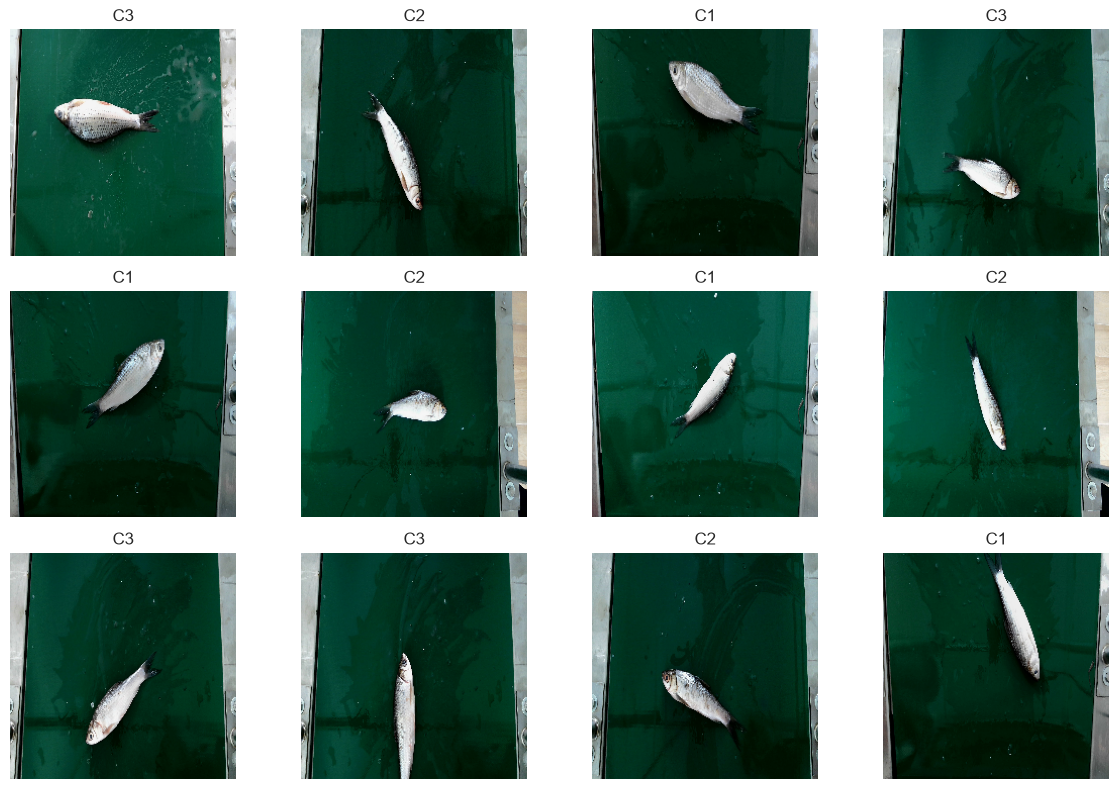

In [5]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.savefig("sample_images.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
normalization_layer = layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
val_ds   = val_ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)

train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0363883].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.024131].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0319455].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0316471].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0542216].


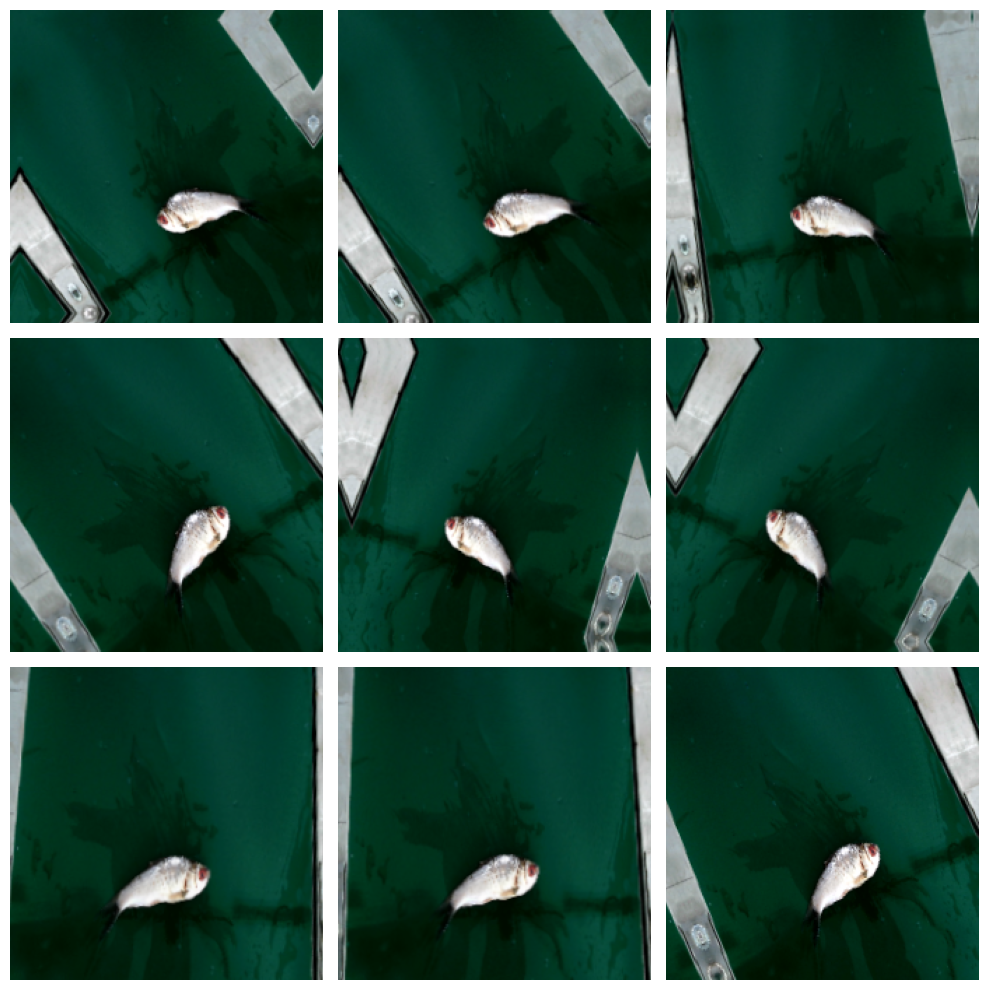

In [7]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    first_image = images[0]
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        augmented = data_augmentation(tf.expand_dims(first_image, 0), training=True)
        plt.imshow(augmented[0].numpy())
        plt.axis("off")
plt.tight_layout()
plt.savefig("augmented_samples.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
def build_custom_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=3):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        data_augmentation,

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation="softmax")
    ], name="Custom_CNN")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

custom_cnn = build_custom_cnn(num_classes=num_classes)
custom_cnn.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 50176)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │      12,845,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             771 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,236,419 (50.49 MB)

 Trainable params: 13,235,459 (50.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
def build_mobilenetv2_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=3):
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False

    inputs = keras.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="MobileNetV2_Transfer")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

mobilenet_model, mobilenet_base = build_mobilenetv2_model(num_classes=num_classes)
mobilenet_model.summary()

Model: "MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ multiply (Multiply)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
os.makedirs("saved_models", exist_ok=True)
os.makedirs("figures", exist_ok=True)

callbacks_custom = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, verbose=1),
    ModelCheckpoint("saved_models/custom_cnn_best.keras", monitor="val_accuracy", save_best_only=True)
]

callbacks_mobilenet = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, verbose=1),
    ModelCheckpoint("saved_models/mobilenetv2_best.keras", monitor="val_accuracy", save_best_only=True)
]

In [11]:
history_custom = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_custom
)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.7539 - loss: 5.2400 - val_accuracy: 0.3490 - val_loss: 2.1540 - learning_rate: 0.0010
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.9284 - loss: 0.9233 - val_accuracy: 0.3333 - val_loss: 18.2702 - learning_rate: 0.0010
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9401 - loss: 0.6191
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
24/24 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.9401 - loss: 0.5924 - val_accuracy: 0.3333 - val_loss: 49.9162 - learning_rate: 0.0010
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.9766 - loss: 0.1721 - val_accuracy: 0.3333 - val_loss: 58.0542 - learning_rate: 3.0000e-04
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9749 - loss: 0.1373
Epoch 5: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
24/24 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.9740 - loss: 0.1215 - val_accurac

In [12]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_mobilenet
)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 23s 748ms/step - accuracy: 0.4974 - loss: 1.0427 - val_accuracy: 0.5417 - val_loss: 0.9375 - learning_rate: 0.0010
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 654ms/step - accuracy: 0.7214 - loss: 0.6627 - val_accuracy: 0.5677 - val_loss: 0.8500 - learning_rate: 0.0010
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 646ms/step - accuracy: 0.7930 - loss: 0.5066 - val_accuracy: 0.7552 - val_loss: 0.6300 - learning_rate: 0.0010
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 17s 703ms/step - accuracy: 0.8333 - loss: 0.4470 - val_accuracy: 0.7708 - val_loss: 0.6026 - learning_rate: 0.0010
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 17s 708ms/step - accuracy: 0.8594 - loss: 0.3536 - val_accuracy: 0.8281 - val_loss: 0.4928 - learning_rate: 0.0010
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 680ms/step - accuracy: 0.8672 - loss: 0.3325 - val_accuracy: 0.7656 - val_loss: 0.5762 - learning_rate: 0.0010
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 545ms/step - accuracy: 0.8720 - loss: 0.3

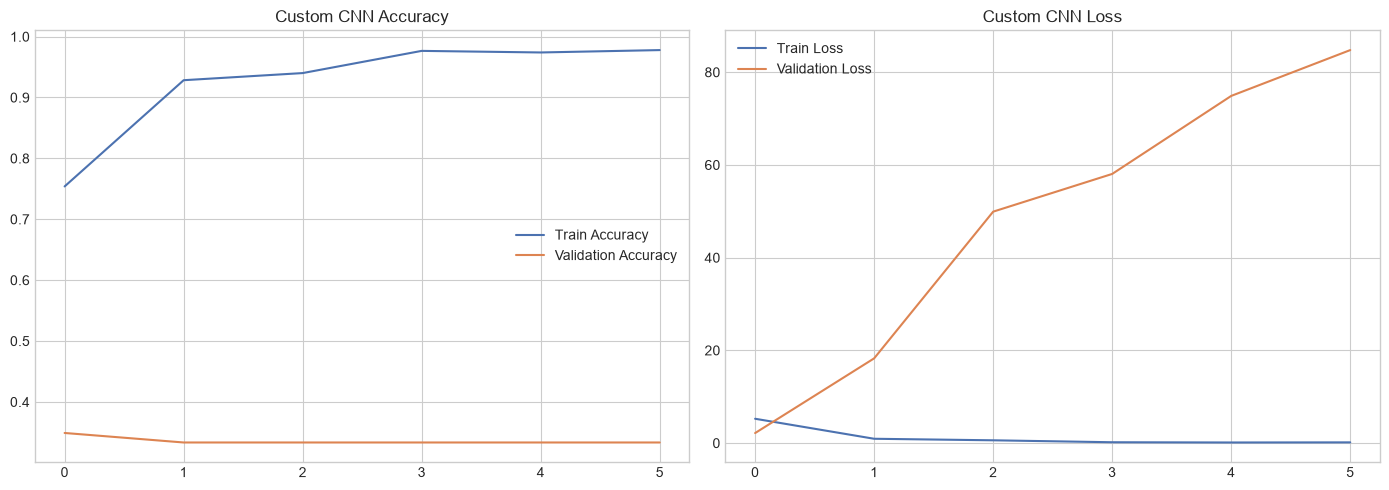

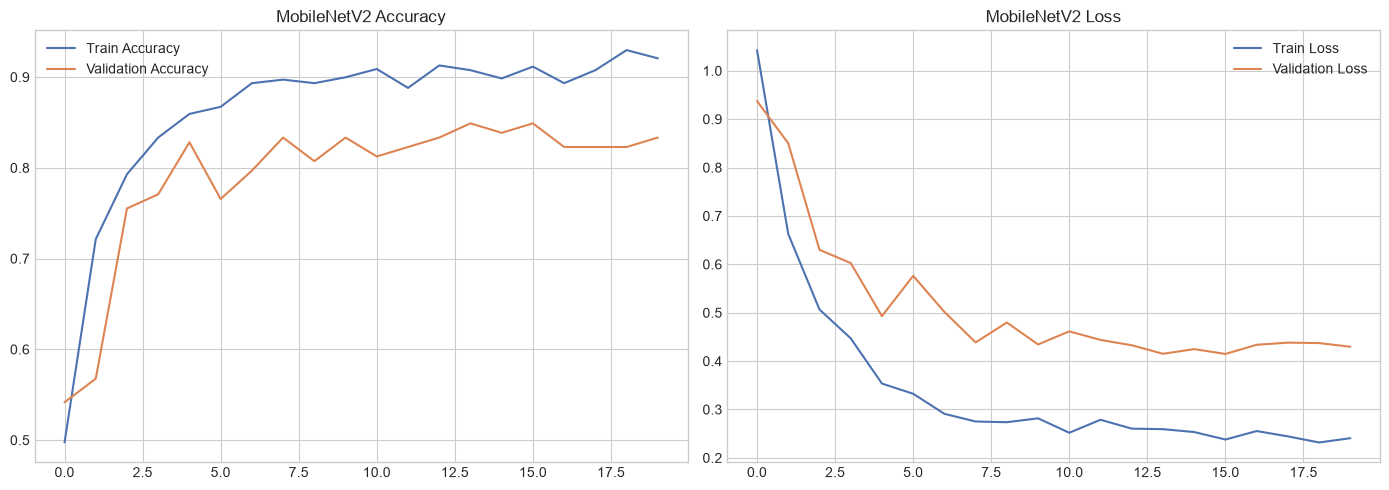

In [13]:
def plot_history(history, title_prefix, save_path):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist["accuracy"], label="Train Accuracy")
    axes[0].plot(hist["val_accuracy"], label="Validation Accuracy")
    axes[0].set_title(f"{title_prefix} Accuracy")
    axes[0].legend()

    axes[1].plot(hist["loss"], label="Train Loss")
    axes[1].plot(hist["val_loss"], label="Validation Loss")
    axes[1].set_title(f"{title_prefix} Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_history(history_custom, "Custom CNN", "figures/custom_cnn_curves.png")
plot_history(history_mobilenet, "MobileNetV2", "figures/mobilenetv2_curves.png")

In [14]:
def get_true_and_pred(model, dataset):
    y_true, y_pred, y_prob = [], [], []

    for x_batch, y_batch in dataset:
        probs = model.predict(x_batch, verbose=0)
        preds = np.argmax(probs, axis=1)

        y_true.extend(y_batch.numpy())
        y_pred.extend(preds)
        y_prob.extend(probs)

    return np.array(y_true), np.array(y_pred), np.array(y_prob)

In [15]:
y_true_cnn, y_pred_cnn, y_prob_cnn = get_true_and_pred(custom_cnn, test_ds)
y_true_mob, y_pred_mob, y_prob_mob = get_true_and_pred(mobilenet_model, test_ds)

cnn_test_loss, cnn_test_acc = custom_cnn.evaluate(test_ds, verbose=0)
mob_test_loss, mob_test_acc = mobilenet_model.evaluate(test_ds, verbose=0)

print("Custom CNN Test Accuracy:", cnn_test_acc)
print("MobileNetV2 Test Accuracy:", mob_test_acc)

Custom CNN Test Accuracy: 0.800000011920929
MobileNetV2 Test Accuracy: 0.8500000238418579


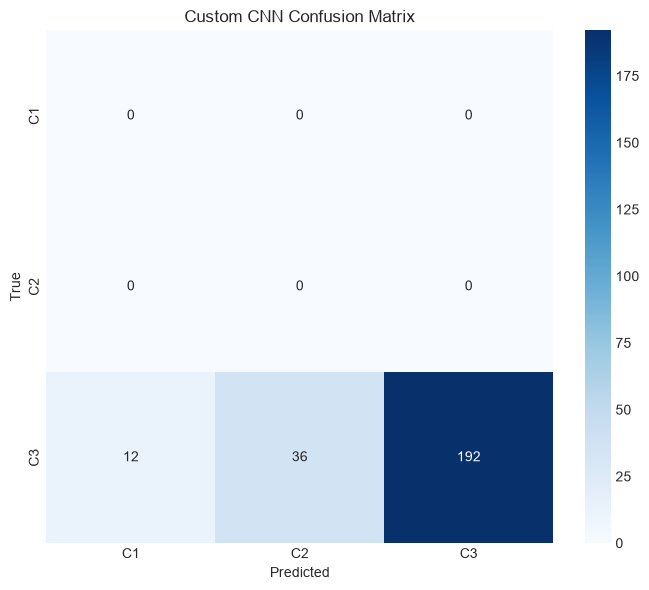

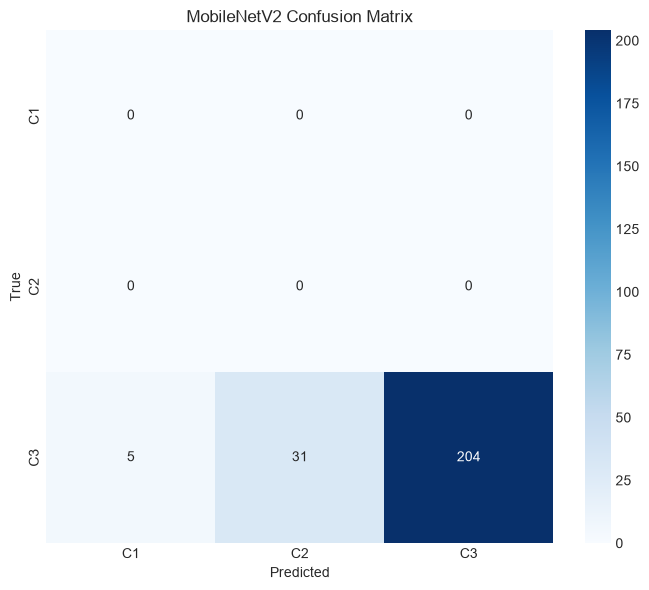

In [16]:
def plot_conf_matrix(y_true, y_pred, class_names, title, save_path):
    labels = np.arange(len(class_names))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_conf_matrix(y_true_cnn, y_pred_cnn, class_names,
                 "Custom CNN Confusion Matrix",
                 "figures/custom_cnn_confusion_matrix.png")

plot_conf_matrix(y_true_mob, y_pred_mob, class_names,
                 "MobileNetV2 Confusion Matrix",
                 "figures/mobilenetv2_confusion_matrix.png")

In [17]:
labels = np.arange(len(class_names))

report_cnn = classification_report(
    y_true_cnn,
    y_pred_cnn,
    labels=labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_mob = classification_report(
    y_true_mob,
    y_pred_mob,
    labels=labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_cnn_df = pd.DataFrame(report_cnn).transpose()
report_mob_df = pd.DataFrame(report_mob).transpose()

display(report_cnn_df)
display(report_mob_df)

report_cnn_df.to_csv("figures/custom_cnn_classification_report.csv")
report_mob_df.to_csv("figures/mobilenetv2_classification_report.csv")

,precision,recall,f1-score,support
C1,0.000000,0.000000,0.000000,0.0
C2,0.000000,0.000000,0.000000,0.0
C3,1.000000,0.800000,0.888889,240.0
accuracy,0.800000,0.800000,0.800000,0.8
macro avg,0.333333,0.266667,0.296296,240.0
weighted avg,1.000000,0.800000,0.888889,240.0


,precision,recall,f1-score,support
C1,0.000000,0.000000,0.000000,0.00
C2,0.000000,0.000000,0.000000,0.00
C3,1.000000,0.850000,0.918919,240.00
accuracy,0.850000,0.850000,0.850000,0.85
macro avg,0.333333,0.283333,0.306306,240.00
weighted avg,1.000000,0.850000,0.918919,240.00


C:\Users\anila\tfenv\Lib\site-packages\sklearn\metrics\_ranking.py:1355: UndefinedMetricWarning: No negative samples in y_true, false positive value should be meaningless
  warnings.warn(


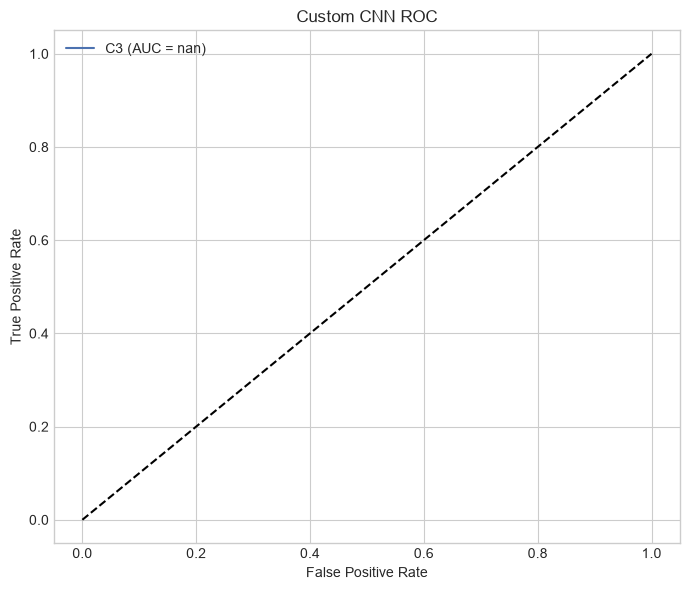

C:\Users\anila\tfenv\Lib\site-packages\sklearn\metrics\_ranking.py:1355: UndefinedMetricWarning: No negative samples in y_true, false positive value should be meaningless
  warnings.warn(


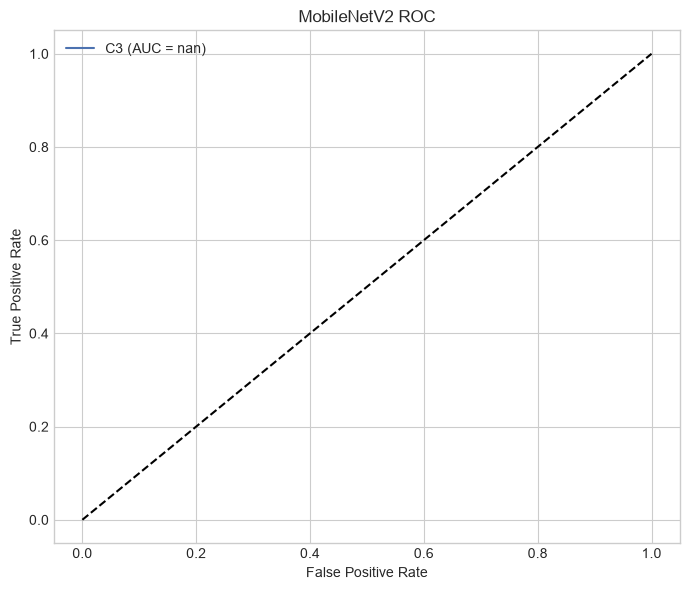

In [18]:
def plot_roc(y_true, y_prob, class_names, title, save_path):
    plt.figure(figsize=(7, 6))
    y_true_bin = label_binarize(y_true, classes=np.arange(len(class_names)))

    for i, class_name in enumerate(class_names):
        if np.sum(y_true_bin[:, i]) > 0:
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"{class_name} (AUC = {roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_roc(y_true_cnn, y_prob_cnn, class_names, "Custom CNN ROC", "figures/custom_cnn_roc.png")
plot_roc(y_true_mob, y_prob_mob, class_names, "MobileNetV2 ROC", "figures/mobilenetv2_roc.png")

In [19]:
comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Test Accuracy": [cnn_test_acc, mob_test_acc],
    "Test Loss": [cnn_test_loss, mob_test_loss],
    "Weighted Precision": [
        report_cnn["weighted avg"]["precision"],
        report_mob["weighted avg"]["precision"]
    ],
    "Weighted Recall": [
        report_cnn["weighted avg"]["recall"],
        report_mob["weighted avg"]["recall"]
    ],
    "Weighted F1-score": [
        report_cnn["weighted avg"]["f1-score"],
        report_mob["weighted avg"]["f1-score"]
    ]
})

display(comparison_df)
comparison_df.to_csv("figures/model_comparison.csv", index=False)

,Model,Test Accuracy,Test Loss,Weighted Precision,Weighted Recall,Weighted F1-score
0,Custom CNN,0.80,0.525751,1.0,0.80,0.888889
1,MobileNetV2,0.85,0.491251,1.0,0.85,0.918919


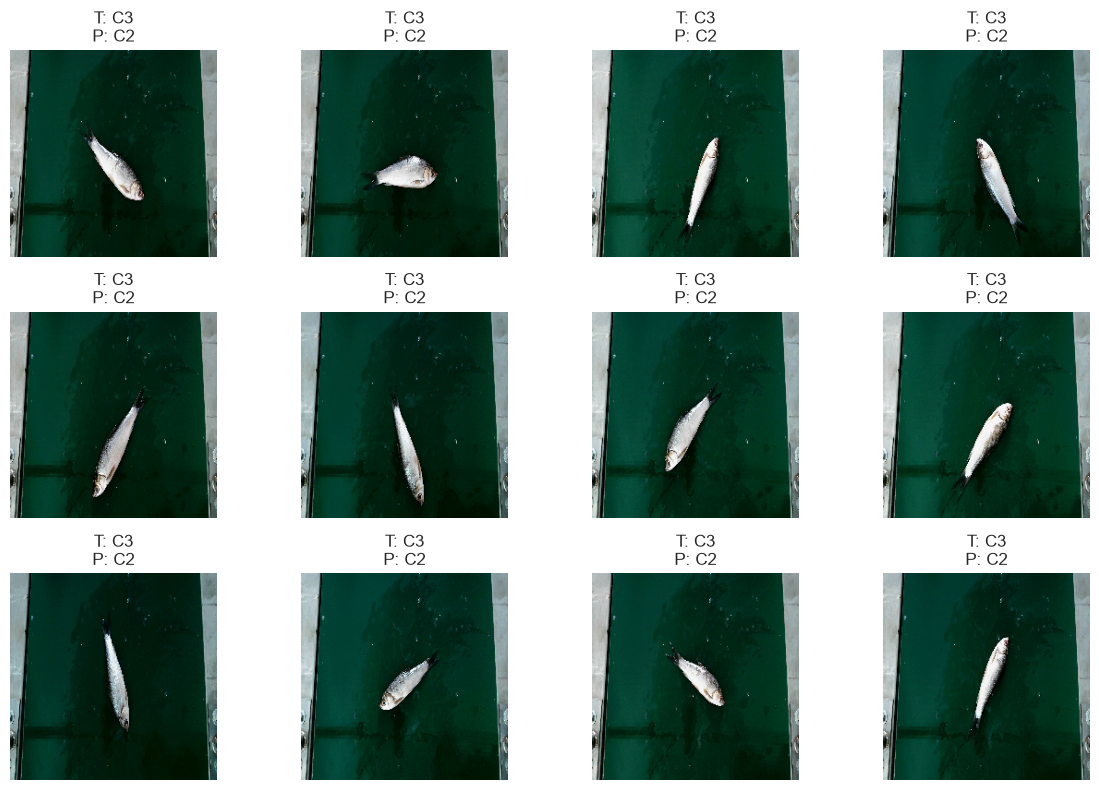

In [20]:
def get_misclassified_images(model, dataset, class_names, max_images=12):
    images_list, true_list, pred_list = [], [], []

    for x_batch, y_batch in dataset:
        probs = model.predict(x_batch, verbose=0)
        preds = np.argmax(probs, axis=1)

        for i in range(len(y_batch)):
            if y_batch[i].numpy() != preds[i]:
                images_list.append(x_batch[i].numpy())
                true_list.append(class_names[y_batch[i].numpy()])
                pred_list.append(class_names[preds[i]])

            if len(images_list) >= max_images:
                return images_list, true_list, pred_list

    return images_list, true_list, pred_list

mis_imgs, mis_true, mis_pred = get_misclassified_images(mobilenet_model, test_ds, class_names)

plt.figure(figsize=(12, 8))
for i in range(len(mis_imgs)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(mis_imgs[i])
    plt.title(f"T: {mis_true[i]}\nP: {mis_pred[i]}")
    plt.axis("off")
plt.tight_layout()
plt.savefig("figures/misclassified_images.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
def get_last_conv_layer_name(model):
    if model.name == "MobileNetV2_Transfer":
        return "Conv_1"
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    return None

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    if model.name == "MobileNetV2_Transfer":
        base_model = model.get_layer("mobilenetv2_1.00_224")
        last_conv_layer = base_model.get_layer(last_conv_layer_name)
        grad_model = tf.keras.models.Model(
            [model.inputs],
            [last_conv_layer.output, model.output]
        )
    else:
        grad_model = tf.keras.models.Model(
            [model.inputs],
            [model.get_layer(last_conv_layer_name).output, model.output]
        )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)

    max_val = tf.math.reduce_max(heatmap)
    if max_val != 0:
        heatmap = heatmap / max_val

    return heatmap.numpy()

def save_gradcam(model, dataset, class_names, save_path="figures/gradcam_result.png"):
    for images, labels in dataset.take(1):
        img = images[0].numpy()
        img_array = tf.expand_dims(images[0], axis=0)

        last_conv_layer_name = get_last_conv_layer_name(model)
        heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

        heatmap = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
        heatmap = np.uint8(255 * heatmap)
        heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

        original = np.uint8(img * 255) if img.max() <= 1.0 else np.uint8(img)
        overlay = cv2.addWeighted(cv2.cvtColor(original, cv2.COLOR_RGB2BGR), 0.6, heatmap, 0.4, 0)

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(original)
        axes[0].set_title("Original Image")
        axes[0].axis("off")

        axes[1].imshow(heatmap)
        axes[1].set_title("Grad-CAM Heatmap")
        axes[1].axis("off")

        axes[2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[2].set_title("Overlay")
        axes[2].axis("off")

        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.show()
        break

save_gradcam(mobilenet_model, test_ds, class_names)

ValueError: Output with path `0` is not connected to `inputs`

In [ ]:
custom_cnn.save("saved_models/custom_cnn_final.keras")
mobilenet_model.save("saved_models/mobilenetv2_final.keras")

with open("saved_models/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Models and labels saved successfully.")

In [26]:
import ipywidgets as widgets
from IPython.display import display

test_button = widgets.Button(
    description="Test Dashboard",
    button_style="success"
)

test_output = widgets.Output()

def on_test_click(button):
    with test_output:
        print("Success! Jupyter widgets are working.")

test_button.on_click(on_test_click)

display(test_button, test_output)

Button(button_style='success', description='Test Dashboard', style=ButtonStyle())

Output()

In [27]:
import sys

print("Python environment:", sys.executable)

for name in [
    "custom_cnn",
    "mobilenet_model",
    "class_names",
    "IMG_SIZE",
    "comparison_df",
    "history_custom",
    "history_mobilenet"
]:
    print(name, "FOUND" if name in globals() else "NOT FOUND")

Python environment: C:\Users\anila\tfenv\Scripts\python.exe
custom_cnn FOUND
mobilenet_model FOUND
class_names FOUND
IMG_SIZE FOUND
comparison_df FOUND
history_custom FOUND
history_mobilenet FOUND


In [28]:
%pip install --upgrade ipywidgets plotly pillow

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ----------------------- ---------------- 1.3/2.2 MB 7.4 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 7.0 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   -------- ------------------------------- 1.6/7.2 MB 9.4 MB/s eta 0:00:01
   -------------------------- ------------- 4.7/7.2 MB 11.9 MB/s eta 0:00:01
   ------------------------------------ --- 6.6/7.2 MB 10.9 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 10.6 MB/s  0:00:00

  Attempting uninstall: widgetsnbextension

    Found existing installation: widgetsnbextension 4.0.15

    Uninstalling widgetsnbextension-4.0.15:

      Successfully uninstalled widgetsnbextension-4.0.15

  Attempting uninstall: pillow

    Found existing installation: pillow 12.2.0

   ---------- ----------------------------- 1/4 [pillow]
    Uninstalling pillow-12.2.0:
   ---------- ------------------

  You can safely remove it manually.


In [1]:
import ipywidgets as widgets
from IPython.display import display

button = widgets.Button(
    description="Test Dashboard",
    button_style="success"
)

output = widgets.Output()

def test_click(_):
    with output:
        print("Jupyter widgets are working!")

button.on_click(test_click)

display(button, output)

Button(button_style='success', description='Test Dashboard', style=ButtonStyle())

Output()

In [2]:
import ipywidgets as widgets
from IPython.display import display

button = widgets.Button(
    description="Test Dashboard",
    button_style="success"
)

output = widgets.Output()

def on_click(btn):
    with output:
        print("Success! Widgets are working.")

button.on_click(on_click)

display(button)
display(output)


Button(button_style='success', description='Test Dashboard', style=ButtonStyle())

Output()

In [3]:
import notebook
import ipywidgets
import sys

print("Python:", sys.executable)
print("Notebook version:", notebook.__version__)
print("ipywidgets version:", ipywidgets.__version__)

Python: C:\Users\anila\tfenv\Scripts\python.exe
Notebook version: 7.5.7
ipywidgets version: 8.1.9


In [4]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider(description="Widget test"))

IntSlider(value=0, description='Widget test')

In [5]:
required_variables = [
    "custom_cnn",
    "mobilenet_model",
    "class_names",
    "IMG_SIZE"
]

for name in required_variables:
    print(f"{name}: {'FOUND' if name in globals() else 'MISSING'}")

custom_cnn: MISSING
mobilenet_model: MISSING
class_names: MISSING
IMG_SIZE: MISSING


In [6]:
import os
import json
import tensorflow as tf

print("Current folder:", os.getcwd())
print("Saved models folder exists:", os.path.isdir("saved_models"))

if os.path.isdir("saved_models"):
    print("Files:", os.listdir("saved_models"))

Current folder: C:\Users\anila\Downloads\archive (3)
Saved models folder exists: True
Files: ['.ipynb_checkpoints', 'class_names.json', 'custom_cnn_best-Copy1.keras', 'custom_cnn_best-Copy2.keras', 'custom_cnn_best-Copy3.keras', 'custom_cnn_best.keras', 'custom_cnn_final.keras', 'mobilenetv2_best.keras', 'mobilenetv2_final.keras']


In [7]:
import os
import json
import tensorflow as tf

model_dir = r"C:\Users\anila\Downloads\archive (3)\saved_models"

# Load the trained models
custom_cnn = tf.keras.models.load_model(
    os.path.join(model_dir, "custom_cnn_final.keras")
)

mobilenet_model = tf.keras.models.load_model(
    os.path.join(model_dir, "mobilenetv2_final.keras")
)

# Load class labels
with open(os.path.join(model_dir, "class_names.json"), "r") as f:
    class_names = json.load(f)

# Get input image dimensions from the model
IMG_SIZE = int(custom_cnn.input_shape[1])

print("Models loaded successfully!")
print("Class names:", class_names)
print("Image size:", IMG_SIZE)
print("Custom CNN input:", custom_cnn.input_shape)
print("MobileNetV2 input:", mobilenet_model.input_shape)

Models loaded successfully!
Class names: ['C1', 'C2', 'C3']
Image size: 224
Custom CNN input: (None, 224, 224, 3)
MobileNetV2 input: (None, 224, 224, 3)


In [8]:
print("Custom CNN:", custom_cnn.input_shape)
print("MobileNetV2:", mobilenet_model.input_shape)
print("Classes:", class_names)
print("Image size:", IMG_SIZE)

Custom CNN: (None, 224, 224, 3)
MobileNetV2: (None, 224, 224, 3)
Classes: ['C1', 'C2', 'C3']
Image size: 224


In [9]:
import io
import numpy as np
import pandas as pd
import ipywidgets as widgets
import plotly.express as px

from PIL import Image
from IPython.display import display, HTML, clear_output

# Dashboard header
display(HTML("""
<div style="background:#17324d;color:white;padding:20px;
border-radius:12px;margin-bottom:15px">
    <h1>🐟 Fish Freshness Assessment</h1>
    <p>Custom CNN | MobileNetV2 | Image Classification</p>
</div>
"""))

# Controls
model_dropdown = widgets.Dropdown(
    options=["Custom CNN", "MobileNetV2"],
    value="Custom CNN",
    description="Model:"
)

image_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload fish image"
)

predict_button = widgets.Button(
    description="Predict Freshness",
    button_style="success",
    icon="check"
)

prediction_output = widgets.Output()

# Prediction function
def predict_fish(_):
    with prediction_output:
        clear_output(wait=True)

        value = image_upload.value

        if not value:
            print("Please upload a fish image first.")
            return

        try:
            # ipywidgets 8 file upload format
            if isinstance(value, (tuple, list)):
                item = value[0]
                content = item["content"]
                filename = item.get("name", "fish_image")
            else:
                filename, item = next(iter(value.items()))
                content = item["content"]

            if hasattr(content, "tobytes"):
                content = content.tobytes()

            # Preprocess image
            image = Image.open(io.BytesIO(content)).convert("RGB")
            display(image.resize((300, 300)))

            resized = image.resize((IMG_SIZE, IMG_SIZE))
            array = np.asarray(resized, dtype=np.float32) / 255.0
            batch = np.expand_dims(array, axis=0)

            # Select trained model
            if model_dropdown.value == "Custom CNN":
                model = custom_cnn
            else:
                model = mobilenet_model

            # Predict
            probabilities = model.predict(batch, verbose=0)[0]
            predicted_index = int(np.argmax(probabilities))
            predicted_class = class_names[predicted_index]
            confidence = float(probabilities[predicted_index]) * 100

            display(HTML(f"""
            <div style="background:#e8f5e9;padding:15px;
            border-radius:10px;margin:10px 0">
                <h2>Predicted class: {predicted_class}</h2>
                <h3>Confidence: {confidence:.2f}%</h3>
                <p>Selected model: {model_dropdown.value}</p>
            </div>
            """))

            # Class probabilities
            results = pd.DataFrame({
                "Class": class_names,
                "Probability (%)": probabilities * 100
            })

            fig = px.bar(
                results,
                x="Class",
                y="Probability (%)",
                color="Class",
                title="Prediction Probability by Class",
                text_auto=".2f"
            )
            fig.update_layout(
                yaxis_range=[0, 100],
                template="plotly_white"
            )
            display(fig)

        except Exception as e:
            print("Prediction error:", str(e))

predict_button.on_click(predict_fish)

display(widgets.VBox([
    model_dropdown,
    image_upload,
    predict_button,
    prediction_output
]))

In [10]:
import json
import os

labels_path = r"C:\Users\anila\Downloads\archive (3)\saved_models\class_names.json"

with open(labels_path, "r") as f:
    print(json.load(f))

['C1', 'C2', 'C3']


In [11]:
import os

dataset_path = r"C:\Users\anila\Downloads\archive (3)"

for folder in ["C1", "C2", "C3"]:
    path = os.path.join(dataset_path, folder)

    if os.path.isdir(path):
        images = [
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        ]
        print(f"{folder}: {len(images)} images")
        print("Sample files:", images[:5])
    else:
        print(f"{folder}: folder not found at {path}")

C1: folder not found at C:\Users\anila\Downloads\archive (3)\C1
C2: folder not found at C:\Users\anila\Downloads\archive (3)\C2
C3: folder not found at C:\Users\anila\Downloads\archive (3)\C3


In [12]:
import os

base_path = r"C:\Users\anila\Downloads"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "node_modules"]
    ]

    if all(folder in dirs for folder in ["C1", "C2", "C3"]):
        print("Dataset found:", root)
        print("C1:", os.path.join(root, "C1"))
        print("C2:", os.path.join(root, "C2"))
        print("C3:", os.path.join(root, "C3"))

Dataset found: C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset
C1: C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset\C1
C2: C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset\C2
C3: C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset\C3


In [13]:
import os

dataset_path = r"C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset"

for class_name in ["C1", "C2", "C3"]:
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    print(f"{class_name}: {len(images)} images")

C1: 400 images
C2: 400 images
C3: 400 images


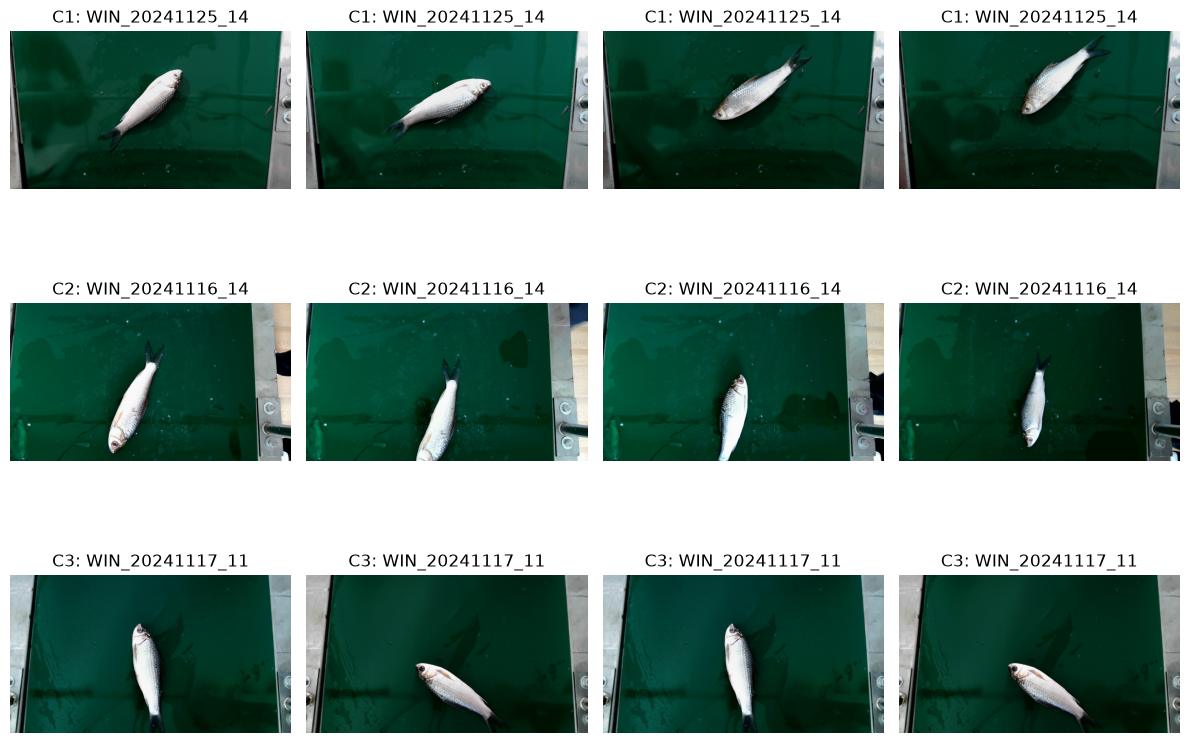

In [14]:
import os
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for row, class_name in enumerate(["C1", "C2", "C3"]):
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ][:4]

    for col in range(4):
        ax = axes[row, col]

        if col < len(images):
            img = Image.open(
                os.path.join(folder, images[col])
            ).convert("RGB")

            ax.imshow(img)
            ax.set_title(f"{class_name}: {images[col][:15]}")
        else:
            ax.axis("off")

        ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
import os

dataset_path = r"C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset"

for class_name in ["C1", "C2", "C3"]:
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    print(f"{class_name}: {len(images)} images")

C1: 400 images
C2: 400 images
C3: 400 images


In [16]:
import os

dataset_path = r"C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset"

for root, dirs, files in os.walk(
    os.path.dirname(dataset_path)
):
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    for filename in files:
        if filename.lower().endswith(
            (".txt", ".csv", ".json", ".md")
        ):
            print(os.path.join(root, filename))

C:\Users\anila\Downloads\archive (3)\sales.csv
C:\Users\anila\Downloads\archive (3)\figures\custom_cnn_classification_report.csv
C:\Users\anila\Downloads\archive (3)\figures\mobilenetv2_classification_report.csv
C:\Users\anila\Downloads\archive (3)\figures\model_comparison.csv
C:\Users\anila\Downloads\archive (3)\saved_models\class_names.json


In [17]:
import pandas as pd
import os

base_path = r"C:\Users\anila\Downloads\archive (3)\figures"

files = [
    "custom_cnn_classification_report.csv",
    "mobilenetv2_classification_report.csv",
    "model_comparison.csv"
]

for filename in files:
    path = os.path.join(base_path, filename)

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    if os.path.exists(path):
        df = pd.read_csv(path)
        display(df)
    else:
        print("File not found")


custom_cnn_classification_report.csv


,Unnamed: 0,precision,recall,f1-score,support
0,C1,0.000000,0.000000,0.000000,0.0
1,C2,0.000000,0.000000,0.000000,0.0
2,C3,1.000000,0.800000,0.888889,240.0
3,accuracy,0.800000,0.800000,0.800000,0.8
4,macro avg,0.333333,0.266667,0.296296,240.0
5,weighted avg,1.000000,0.800000,0.888889,240.0



mobilenetv2_classification_report.csv


,Unnamed: 0,precision,recall,f1-score,support
0,C1,0.000000,0.000000,0.000000,0.00
1,C2,0.000000,0.000000,0.000000,0.00
2,C3,1.000000,0.850000,0.918919,240.00
3,accuracy,0.850000,0.850000,0.850000,0.85
4,macro avg,0.333333,0.283333,0.306306,240.00
5,weighted avg,1.000000,0.850000,0.918919,240.00



model_comparison.csv


,Model,Test Accuracy,Test Loss,Weighted Precision,Weighted Recall,Weighted F1-score
0,Custom CNN,0.80,0.525751,1.0,0.80,0.888889
1,MobileNetV2,0.85,0.491251,1.0,0.85,0.918919


In [18]:
import os
import pandas as pd
import plotly.express as px
from IPython.display import display, HTML

base_path = r"C:\Users\anila\Downloads\archive (3)"
report_path = os.path.join(
    base_path, "figures", "model_comparison.csv"
)

comparison = pd.read_csv(report_path)

display(HTML("<h2>Fish Freshness Model Performance</h2>"))
display(comparison)

fig = px.bar(
    comparison,
    x="Model",
    y="Test Accuracy",
    color="Model",
    text=comparison["Test Accuracy"].map(
        lambda value: f"{value:.0%}"
    ),
    title="Test Accuracy: Custom CNN vs MobileNetV2"
)

fig.update_layout(
    yaxis_title="Test accuracy",
    yaxis_tickformat=".0%",
    yaxis_range=[0, 1],
    template="plotly_white"
)

display(fig)

,Model,Test Accuracy,Test Loss,Weighted Precision,Weighted Recall,Weighted F1-score
0,Custom CNN,0.80,0.525751,1.0,0.80,0.888889
1,MobileNetV2,0.85,0.491251,1.0,0.85,0.918919


In [19]:
import io
import numpy as np
import pandas as pd
import ipywidgets as widgets
import plotly.express as px

from PIL import Image
from IPython.display import display, HTML, clear_output

# Dashboard header
display(HTML("""
<div style="background:#17324d;color:white;padding:20px;
border-radius:12px">
<h1>🐟 Fish Freshness Assessment Dashboard</h1>
<p>Upload an image to classify it using your trained CNN models.</p>
</div>
"""))

# Model selection
model_dropdown = widgets.Dropdown(
    options=["Custom CNN", "MobileNetV2"],
    value="MobileNetV2",
    description="Select model:"
)

# Image upload
image_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload fish image"
)

# Prediction button
predict_button = widgets.Button(
    description="Predict Fish Class",
    button_style="success",
    icon="check"
)

result_output = widgets.Output()

def predict_fish(_):
    with result_output:
        clear_output(wait=True)

        value = image_upload.value

        if not value:
            print("Please upload an image first.")
            return

        try:
            # Read uploaded image (ipywidgets 8)
            if isinstance(value, (tuple, list)):
                item = value[0]
                content = item["content"]
                filename = item.get("name", "fish_image")
            else:
                filename, item = next(iter(value.items()))
                content = item["content"]

            if hasattr(content, "tobytes"):
                content = content.tobytes()

            image = Image.open(io.BytesIO(content)).convert("RGB")

            # Match model input dimensions
            model = (
                custom_cnn
                if model_dropdown.value == "Custom CNN"
                else mobilenet_model
            )

            height, width = model.input_shape[1:3]
            image_resized = image.resize((width, height))

            x = np.asarray(image_resized, dtype=np.float32) / 255.0
            x = np.expand_dims(x, axis=0)

            # Predict
            probabilities = model.predict(x, verbose=0)[0]
            predicted_index = int(np.argmax(probabilities))
            predicted_class = class_names[predicted_index]
            confidence = float(probabilities[predicted_index]) * 100

            display(image.resize((300, 300)))

            display(HTML(f"""
            <div style="padding:18px;background:#e8f5e9;
            border-radius:12px;margin:12px 0">
                <h2>Predicted class: {predicted_class}</h2>
                <h3>Confidence: {confidence:.2f}%</h3>
                <p>Model: {model_dropdown.value}</p>
                <p>Image: {filename}</p>
            </div>
            """))

            # Probability chart
            results = pd.DataFrame({
                "Class": class_names,
                "Probability (%)": probabilities * 100
            })

            fig = px.bar(
                results,
                x="Class",
                y="Probability (%)",
                color="Class",
                text=results["Probability (%)"].map(
                    lambda p: f"{p:.2f}%"
                ),
                title="Predicted Probability by Class"
            )

            fig.update_layout(
                yaxis_range=[0, 100],
                template="plotly_white"
            )

            display(fig)

        except Exception as e:
            print("Prediction error:", repr(e))

predict_button.on_click(predict_fish)

# Display all dashboard controls
display(widgets.VBox([
    model_dropdown,
    image_upload,
    predict_button,
    result_output
]))

In [20]:
import io
import numpy as np
import ipywidgets as widgets
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, HTML, clear_output

# Check that the models are loaded
assert "custom_cnn" in globals(), "Load Custom CNN first"
assert "mobilenet_model" in globals(), "Load MobileNetV2 first"
assert "class_names" in globals(), "Load class labels first"

# IMPORTANT:
# Keep labels unmapped until you verify what C1, C2, and C3 mean.
CLASS_MAPPING = {
    "C1": None,
    "C2": None,
    "C3": None
}

model_selector = widgets.Dropdown(
    options=["MobileNetV2", "Custom CNN"],
    value="MobileNetV2",
    description="Model:"
)

upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Choose fish image"
)

predict = widgets.Button(
    description="CHECK FISH FRESHNESS",
    button_style="success"
)

result = widgets.Output()

def check_fish(_):
    with result:
        clear_output(wait=True)

        value = upload.value
        if not value:
            print("Please choose a fish image first.")
            return

        try:
            if isinstance(value, (tuple, list)):
                item = value[0]
                content = item["content"]
            else:
                _, item = next(iter(value.items()))
                content = item["content"]

            if hasattr(content, "tobytes"):
                content = content.tobytes()

            image = Image.open(io.BytesIO(content)).convert("RGB")

            model = (
                mobilenet_model
                if model_selector.value == "MobileNetV2"
                else custom_cnn
            )

            h, w = model.input_shape[1:3]
            image = image.resize((w, h))

            # Assumes the model was trained on pixels normalized to [0, 1].
            x = np.asarray(image, dtype=np.float32) / 255.0
            x = x[None, ...]

            probabilities = model.predict(x, verbose=0)[0]
            idx = int(np.argmax(probabilities))
            predicted_class = class_names[idx]
            confidence = float(probabilities[idx]) * 100

            display(HTML("<h2>🐟 Fish Freshness Result</h2>"))
            display(image.resize((280, 280)))

            print("Selected model:", model_selector.value)
            print("Predicted class:", predicted_class)
            print(f"Model confidence: {confidence:.2f}%")

            mapped_result = CLASS_MAPPING.get(predicted_class)

            if mapped_result is None:
                display(HTML("""
                <div style="padding:16px;background:#fff3cd;
                border-radius:10px;margin-top:10px">
                <h3>Freshness status not yet verified</h3>
                <p>The model predicted a class, but we still need to
                confirm whether that class means Fresh or Not Fresh
                from your dataset's documentation.</p>
                </div>
                """))
            else:
                display(HTML(f"""
                <div style="padding:16px;background:#e8f5e9;
                border-radius:10px;margin-top:10px">
                <h2>Result: {mapped_result}</h2>
                <p>Predicted class: {predicted_class}</p>
                <p>Confidence: {confidence:.2f}%</p>
                </div>
                """))

            plt.figure(figsize=(7, 3))
            plt.bar(
                class_names,
                probabilities * 100
            )
            plt.ylabel("Predicted probability (%)")
            plt.xlabel("Class")
            plt.title("Fish Image Classification")
            plt.ylim(0, 100)
            plt.show()

        except Exception as e:
            print("Prediction failed:", repr(e))

predict.on_click(check_fish)

display(HTML("""
<div style="padding:18px;background:#17324d;color:white;
border-radius:12px">
<h1>Fish Freshness Dashboard</h1>
<p>Upload a fish image and classify it with your trained model.</p>
</div>
"""))
display(model_selector)
display(upload)
display(predict)
display(result)

Dropdown(description='Model:', options=('MobileNetV2', 'Custom CNN'), value='MobileNetV2')

FileUpload(value=(), accept='image/*', description='Choose fish image')

Button(button_style='success', description='CHECK FISH FRESHNESS', style=ButtonStyle())

Output()

In [21]:
import os

dataset_path = r"C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset"

for class_name in ["C1", "C2", "C3"]:
    folder = os.path.join(dataset_path, class_name)

    print(f"\n--- {class_name} ---")

    if os.path.isdir(folder):
        files = os.listdir(folder)
        print("Number of files:", len(files))
        print("First 10 filenames:", files[:10])
    else:
        print("Folder not found")


--- C1 ---
Number of files: 400
First 10 filenames: ['WIN_20241125_14_48_53_Pro.jpg', 'WIN_20241125_14_49_03_Pro.jpg', 'WIN_20241125_14_49_07_Pro.jpg', 'WIN_20241125_14_49_11_Pro.jpg', 'WIN_20241125_14_49_13_Pro.jpg', 'WIN_20241125_14_49_17_Pro.jpg', 'WIN_20241125_14_49_20_Pro.jpg', 'WIN_20241125_14_49_23_Pro.jpg', 'WIN_20241125_14_49_27_Pro.jpg', 'WIN_20241125_14_49_31_Pro.jpg']

--- C2 ---
Number of files: 400
First 10 filenames: ['WIN_20241116_14_32_47_Pro.jpg', 'WIN_20241116_14_32_53_Pro.jpg', 'WIN_20241116_14_33_02_Pro.jpg', 'WIN_20241116_14_33_07_Pro.jpg', 'WIN_20241116_14_33_13_Pro.jpg', 'WIN_20241116_14_33_24_Pro.jpg', 'WIN_20241116_14_33_28_Pro.jpg', 'WIN_20241116_14_33_32_Pro.jpg', 'WIN_20241116_14_33_35_Pro.jpg', 'WIN_20241116_14_33_42_Pro.jpg']

--- C3 ---
Number of files: 400
First 10 filenames: ['WIN_20241117_11_59_044_Pro.jpg', 'WIN_20241117_11_59_37_Pro.jpg', 'WIN_20241117_11_59_41_Pro.jpg', 'WIN_20241117_11_59_444_Pro -  (1).jpg', 'WIN_20241117_11_59_44_Pro.jpg', 'WIN

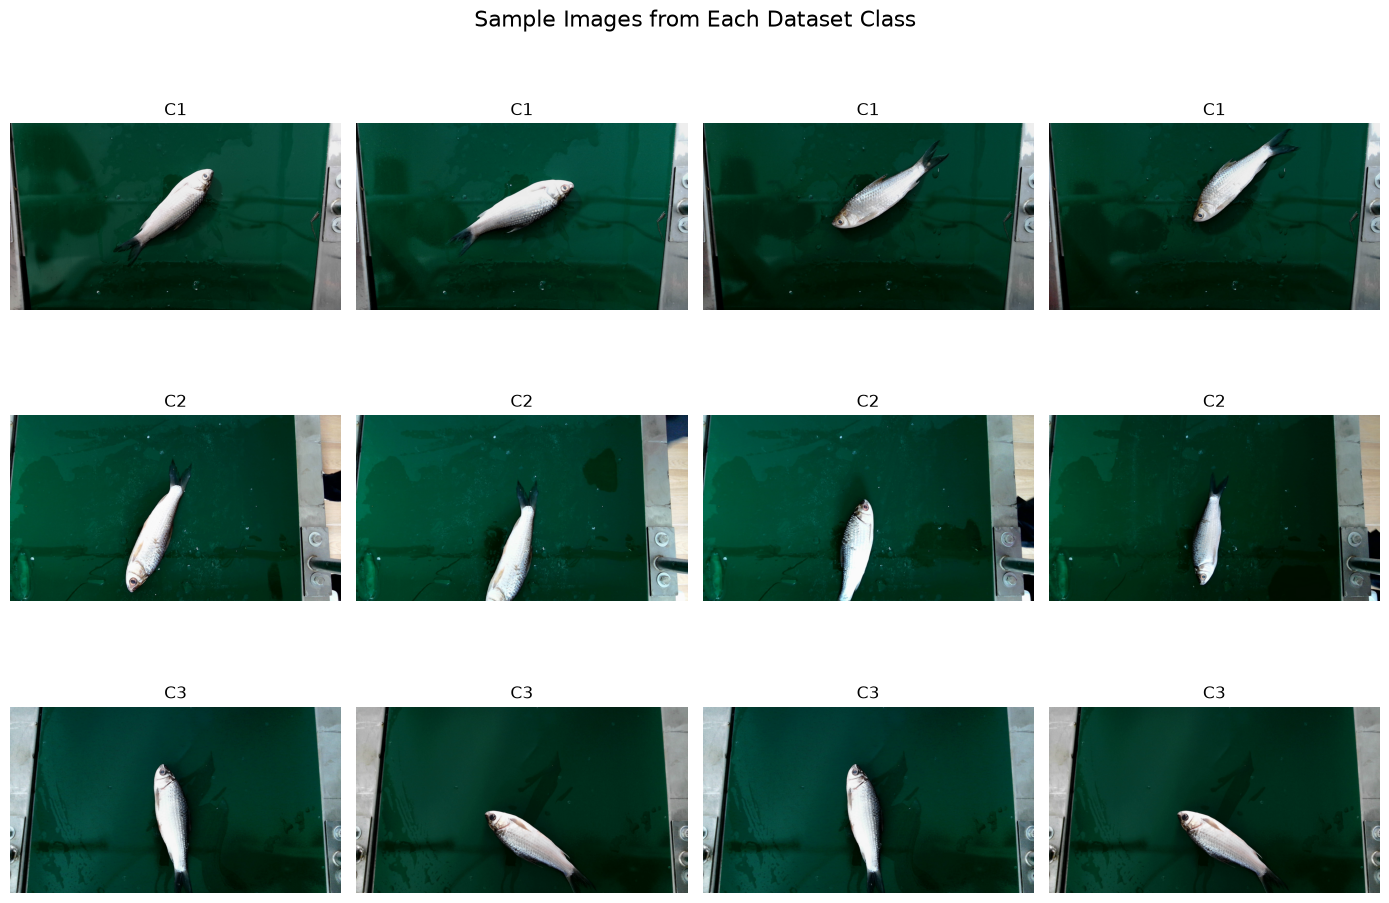

In [22]:
import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = r"C:\Users\anila\Downloads\archive (3)\Freshness Fish Dataset"

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, class_name in enumerate(["C1", "C2", "C3"]):
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ][:4]

    for col, filename in enumerate(images):
        image_path = os.path.join(folder, filename)
        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Sample Images from Each Dataset Class", fontsize=16)
plt.tight_layout()
plt.show()

In [23]:
import json

path = r"C:\Users\anila\Downloads\archive (3)\saved_models\class_names.json"

with open(path, "r") as f:
    labels = json.load(f)

print("Model class labels:", labels)
print("Class order:", list(enumerate(labels)))

Model class labels: ['C1', 'C2', 'C3']
Class order: [(0, 'C1'), (1, 'C2'), (2, 'C3')]


In [24]:
import json

path = r"C:\Users\anila\Downloads\archive (3)\saved_models\class_names.json"

with open(path, "r") as f:
    labels = json.load(f)

print("Model class labels:", labels)
print("Class order:", list(enumerate(labels)))

Model class labels: ['C1', 'C2', 'C3']
Class order: [(0, 'C1'), (1, 'C2'), (2, 'C3')]


In [25]:
import os

base_path = r"C:\Users\anila\Downloads\archive (3)"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    for filename in files:
        if filename.lower() in [
            "readme.txt",
            "readme.md",
            "metadata.csv",
            "labels.csv",
            "description.txt"
        ]:
            print(os.path.join(root, filename))

In [26]:
CLASS_MAPPING = {
    "C1": None,
    "C2": None,
    "C3": None
}

In [27]:
CLASS_MAPPING = {
    "C1": "Fresh",
    "C2": "Moderately Fresh",
    "C3": "Not Fresh"
}

In [28]:
mapped_result = CLASS_MAPPING.get(predicted_class)

NameError: name 'predicted_class' is not defined

In [29]:
CLASS_MAPPING = {
    "C1": "Fresh",
    "C2": "Moderately Fresh",
    "C3": "Not Fresh"
}

print("Class mapping ready!")

Class mapping ready!


In [33]:
predicted_class = class_names[idx]
confidence = float(probabilities[idx]) * 100                                                  

NameError: name 'idx' is not defined

In [1]:
import io
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from PIL import Image
from IPython.display import display, HTML, clear_output

# Map model classes to freshness categories
CLASS_MAPPING = {
    "C1": "Fresh",
    "C2": "Moderately Fresh",
    "C3": "Not Fresh"
}

# Prediction function
def check_fish(_):
    with result:
        clear_output(wait=True)

        value = upload.value

        if not value:
            print("Please upload a fish image first.")
            return

        try:
            # Read uploaded image (ipywidgets 8)
            if isinstance(value, (tuple, list)):
                item = value[0]
                content = item["content"]
            else:
                _, item = next(iter(value.items()))
                content = item["content"]

            if hasattr(content, "tobytes"):
                content = content.tobytes()

            image = Image.open(io.BytesIO(content)).convert("RGB")

            # Select model
            model = (
                mobilenet_model
                if model_selector.value == "MobileNetV2"
                else custom_cnn
            )

            # Resize image to model input dimensions
            height, width = model.input_shape[1:3]
            resized_image = image.resize((width, height))

            # Assumes model training used pixel values normalized to [0, 1]
            x = np.asarray(resized_image, dtype=np.float32) / 255.0
            x = np.expand_dims(x, axis=0)

            # Predict class probabilities
            probabilities = model.predict(x, verbose=0)[0]
            idx = int(np.argmax(probabilities))

            predicted_class = class_names[idx]
            mapped_result = CLASS_MAPPING.get(
                predicted_class, "Unknown class"
            )
            confidence = float(probabilities[idx]) * 100

            # Display uploaded image
            display(image.resize((300, 300)))

            # Display freshness result
            display(HTML(f"""
            <div style="padding:20px; background:#e8f5e9;
                        border-radius:12px; margin:12px 0;">
                <h2>🐟 Fish Freshness Result</h2>
                <h1>{mapped_result}</h1>
                <p><b>Predicted class:</b> {predicted_class}</p>
                <p><b>Confidence:</b> {confidence:.2f}%</p>
                <p><b>Model:</b> {model_selector.value}</p>
            </div>
            """))

            # Display probabilities for all classes
            plt.figure(figsize=(7, 4))
            plt.bar(
                [CLASS_MAPPING.get(c, c) for c in class_names],
                probabilities * 100
            )
            plt.ylabel("Predicted probability (%)")
            plt.xlabel("Fish freshness category")
            plt.title("Fish Freshness Prediction")
            plt.ylim(0, 100)
            plt.xticks(rotation=15)
            plt.tight_layout()
            plt.show()

        except Exception as e:
            print("Prediction error:", repr(e))


# Connect the button and display the dashboard
predict.on_click(check_fish)

display(HTML("""
<div style="background:#17324d;color:white;padding:18px;
            border-radius:12px;">
    <h1>Fish Freshness Assessment Dashboard</h1>
    <p>Upload a fish image to predict its freshness category.</p>
</div>
"""))

display(model_selector, upload, predict, result)

NameError: name 'predict' is not defined

In [1]:
print("predict:", "predict" in globals())
print("predict_button:", "predict_button" in globals())
print("check_fish:", "check_fish" in globals())
print("predict_fish:", "predict_fish" in globals())

predict: False
predict_button: False
check_fish: False
predict_fish: False


In [2]:
predict.on_click(check_fish)

NameError: name 'predict' is not defined

In [3]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create the prediction button
predict = widgets.Button(
    description="Predict Fish Freshness",
    button_style="success",
    icon="check"
)

# Create an output area
result = widgets.Output()

# Define a test function
def check_fish(button):
    with result:
        clear_output()
        print("Button is working correctly!")
        print("Next, we will connect your fish prediction model.")

# Connect the button to the function
predict.on_click(check_fish)

# Display the button and output
display(predict, result)

Button(button_style='success', description='Predict Fish Freshness', icon='check', style=ButtonStyle())

Output()

In [4]:
import os
import json
import tensorflow as tf

# Project folders
BASE_DIR = r"C:\Users\anila\Downloads\archive (3)"
MODEL_DIR = os.path.join(BASE_DIR, "saved_models")

# Load class names
with open(os.path.join(MODEL_DIR, "class_names.json"), "r") as f:
    class_names = json.load(f)

# Load trained models
custom_cnn = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "custom_cnn_final.keras")
)

mobilenet_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "mobilenetv2_final.keras")
)

# Map dataset labels to readable categories
CLASS_MAPPING = {
    "C1": "Fresh",
    "C2": "Moderately Fresh",
    "C3": "Not Fresh"
}

IMG_SIZE = 224

print("Models loaded successfully!")
print("Class names:", class_names)
print("Available models: Custom CNN and MobileNetV2")

Models loaded successfully!
Class names: ['C1', 'C2', 'C3']
Available models: Custom CNN and MobileNetV2


In [5]:
import os
import json
import tensorflow as tf

# Project folders
BASE_DIR = r"C:\Users\anila\Downloads\archive (3)"
MODEL_DIR = os.path.join(BASE_DIR, "saved_models")

# Load class names
with open(os.path.join(MODEL_DIR, "class_names.json"), "r") as f:
    class_names = json.load(f)

# Load trained models
custom_cnn = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "custom_cnn_final.keras")
)

mobilenet_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "mobilenetv2_final.keras")
)

# Map dataset labels to readable categories
CLASS_MAPPING = {
    "C1": "Fresh",
    "C2": "Moderately Fresh",
    "C3": "Not Fresh"
}

IMG_SIZE = 224

print("Models loaded successfully!")
print("Class names:", class_names)
print("Available models: Custom CNN and MobileNetV2")

Models loaded successfully!
Class names: ['C1', 'C2', 'C3']
Available models: Custom CNN and MobileNetV2


In [6]:
import io
import numpy as np
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

# Image upload widget
image_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload Fish Image"
)

# Select the model
model_selector = widgets.Dropdown(
    options=["MobileNetV2", "Custom CNN"],
    value="MobileNetV2",
    description="Model:"
)

# Prediction button
predict_button = widgets.Button(
    description="Predict Freshness",
    button_style="success",
    icon="check"
)

# Prediction output area
prediction_output = widgets.Output()


# Prediction function
def predict_fish(button):
    with prediction_output:
        clear_output(wait=True)

        try:
            # Check whether an image was uploaded
            if not image_upload.value:
                print("Please upload a fish image first.")
                return

            # Read uploaded image
            uploaded = image_upload.value

            # Support different ipywidgets versions
            if isinstance(uploaded, dict):
                file_info = next(iter(uploaded.values()))
            else:
                file_info = uploaded[0]

            image_bytes = file_info["content"]
            image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

            # Prepare image for model
            image_resized = image.resize((IMG_SIZE, IMG_SIZE))
            image_array = np.array(image_resized, dtype=np.float32)
            image_array = image_array / 255.0
            image_array = np.expand_dims(image_array, axis=0)

            # Choose trained model
            if model_selector.value == "MobileNetV2":
                selected_model = mobilenet_model
            else:
                selected_model = custom_cnn

            # Predict
            predictions = selected_model.predict(
                image_array, verbose=0
            )[0]

            predicted_index = int(np.argmax(predictions))
            predicted_class = class_names[predicted_index]
            category = CLASS_MAPPING.get(
                predicted_class, predicted_class
            )
            confidence = float(predictions[predicted_index]) * 100

            # Display results
            display(image)

            print("Selected model:", model_selector.value)
            print("Predicted class:", predicted_class)
            print("Freshness category:", category)
            print(f"Prediction confidence: {confidence:.2f}%")

            print("\nClass probabilities:")
            for i, class_name in enumerate(class_names):
                label = CLASS_MAPPING.get(class_name, class_name)
                print(f"{label}: {predictions[i] * 100:.2f}%")

        except Exception as e:
            print("Prediction error:", repr(e))


# Connect button to function
predict_button.on_click(predict_fish)

# Display dashboard controls
display(model_selector)
display(image_upload)
display(predict_button)
display(prediction_output)

Dropdown(description='Model:', options=('MobileNetV2', 'Custom CNN'), value='MobileNetV2')

FileUpload(value=(), accept='image/*', description='Upload Fish Image')

Button(button_style='success', description='Predict Freshness', icon='check', style=ButtonStyle())

Output()

In [7]:
import matplotlib.pyplot as plt

def show_probability_chart(predictions, class_names):
    labels = [
        CLASS_MAPPING.get(name, name)
        for name in class_names
    ]

    probabilities = predictions * 100

    plt.figure(figsize=(8, 4))
    bars = plt.bar(labels, probabilities)

    plt.title("Fish Freshness Prediction Probabilities")
    plt.xlabel("Freshness Category")
    plt.ylabel("Probability (%)")
    plt.ylim(0, 100)

    for bar, value in zip(bars, probabilities):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()

In [8]:
print("\nClass probabilities:")
for i, class_name in enumerate(class_names):
    label = CLASS_MAPPING.get(class_name, class_name)
    print(f"{label}: {predictions[i] * 100:.2f}%")


Class probabilities:


NameError: name 'predictions' is not defined

In [9]:
show_probability_chart(predictions, class_names)

NameError: name 'predictions' is not defined

In [10]:
print("\nClass probabilities:")
for i, class_name in enumerate(class_names):
    label = CLASS_MAPPING.get(class_name, class_name)
    print(f"{label}: {predictions[i] * 100:.2f}%")


Class probabilities:


NameError: name 'predictions' is not defined

In [11]:
print("\nClass probabilities:")
for i, class_name in enumerate(class_names):
    label = CLASS_MAPPING.get(class_name, class_name)
    print(f"{label}: {predictions[i] * 100:.2f}%")

# Display probability chart
show_probability_chart(predictions, class_names)


Class probabilities:


NameError: name 'predictions' is not defined

In [12]:
print("\nClass probabilities:")
for i, class_name in enumerate(class_names):
    label = CLASS_MAPPING.get(class_name, class_name)
    print(f"{label}: {predictions[i] * 100:.2f}%")

# Display probability chart
show_probability_chart(predictions, class_names)


Class probabilities:


NameError: name 'predictions' is not defined

Models available: True
Class names: ['C1', 'C2', 'C3']


ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between 'x' with shape (3,) and 'height' with shape (300,).

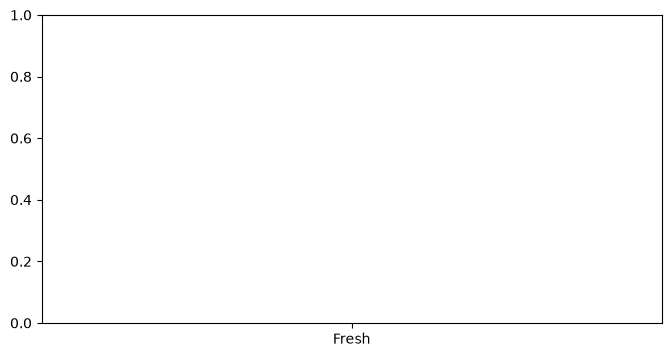

In [13]:
# Check that the models and class names are loaded
print("Models available:", "mobilenet_model" in globals())
print("Class names:", class_names)

# Create sample probabilities to test the chart
test_predictions = [0.20, 0.60, 0.20]

# Display the chart using sample values
show_probability_chart(
    test_predictions,
    class_names
)

In [14]:
import matplotlib.pyplot as plt
import numpy as np

def show_probability_chart(predictions, class_names):
    predictions = np.asarray(predictions).flatten()

    # Make sure the number of labels matches the predictions
    if len(predictions) != len(class_names):
        print("Error: Number of predictions does not match class names.")
        print("Predictions:", len(predictions))
        print("Class names:", len(class_names))
        return

    labels = [
        CLASS_MAPPING.get(name, name)
        for name in class_names
    ]

    probabilities = predictions * 100

    plt.figure(figsize=(8, 4))
    bars = plt.bar(labels, probabilities)

    plt.title("Fish Freshness Prediction Probabilities")
    plt.xlabel("Freshness Category")
    plt.ylabel("Probability (%)")
    plt.ylim(0, 100)

    for bar, value in zip(bars, probabilities):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()

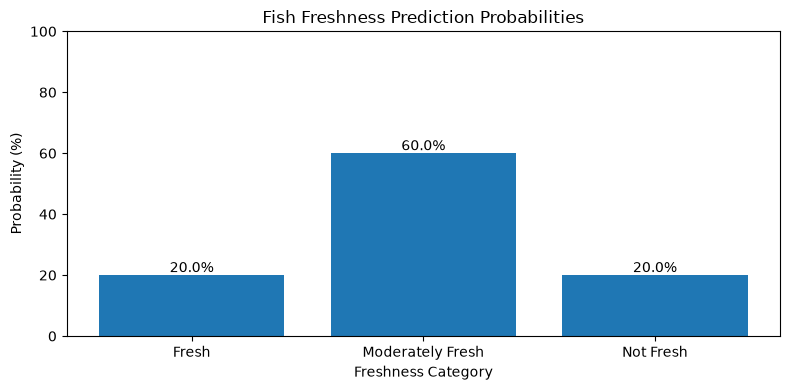

In [15]:
test_predictions = [0.20, 0.60, 0.20]

show_probability_chart(
    test_predictions,
    ["C1", "C2", "C3"]
)

In [16]:
import io
import numpy as np
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

# Create a new prediction button
live_predict_button = widgets.Button(
    description="Predict Fish Freshness",
    button_style="success"
)

# Output area for results
live_prediction_output = widgets.Output()

# Prediction function connected to your trained models
def live_predict_fish(button):
    with live_prediction_output:
        clear_output(wait=True)

        try:
            if not image_upload.value:
                print("Please upload a fish image first.")
                return

            # Read the uploaded image
            uploaded = image_upload.value

            if isinstance(uploaded, dict):
                file_info = next(iter(uploaded.values()))
            else:
                file_info = uploaded[0]

            image = Image.open(
                io.BytesIO(file_info["content"])
            ).convert("RGB")

            # Preprocess the image
            image = image.resize((IMG_SIZE, IMG_SIZE))
            image_array = np.array(image, dtype=np.float32) / 255.0
            image_array = np.expand_dims(image_array, axis=0)

            # Select the trained model
            if model_selector.value == "MobileNetV2":
                selected_model = mobilenet_model
            else:
                selected_model = custom_cnn

            # Generate real predictions
            predictions = selected_model.predict(
                image_array, verbose=0
            )[0]

            print("Selected model:", model_selector.value)
            print("Predicted freshness:", CLASS_MAPPING.get(
                class_names[int(np.argmax(predictions))],
                class_names[int(np.argmax(predictions))]
            ))

            print("\nClass probabilities:")
            for i, name in enumerate(class_names):
                label = CLASS_MAPPING.get(name, name)
                print(f"{label}: {predictions[i] * 100:.2f}%")

            # Display actual prediction probabilities
            show_probability_chart(predictions, class_names)

        except Exception as e:
            print("Error:", repr(e))


# Connect the new button
live_predict_button.on_click(live_predict_fish)

# Display the new button and its output
display(live_predict_button, live_prediction_output)

Button(button_style='success', description='Predict Fish Freshness', style=ButtonStyle())

Output()

In [16]:
import io
import numpy as np
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

# Create a new prediction button
live_predict_button = widgets.Button(
    description="Predict Fish Freshness",
    button_style="success"
)

# Output area for results
live_prediction_output = widgets.Output()

# Prediction function connected to your trained models
def live_predict_fish(button):
    with live_prediction_output:
        clear_output(wait=True)

        try:
            if not image_upload.value:
                print("Please upload a fish image first.")
                return

            # Read the uploaded image
            uploaded = image_upload.value

            if isinstance(uploaded, dict):
                file_info = next(iter(uploaded.values()))
            else:
                file_info = uploaded[0]

            image = Image.open(
                io.BytesIO(file_info["content"])
            ).convert("RGB")

            # Preprocess the image
            image = image.resize((IMG_SIZE, IMG_SIZE))
            image_array = np.array(image, dtype=np.float32) / 255.0
            image_array = np.expand_dims(image_array, axis=0)

            # Select the trained model
            if model_selector.value == "MobileNetV2":
                selected_model = mobilenet_model
            else:
                selected_model = custom_cnn

            # Generate real predictions
            predictions = selected_model.predict(
                image_array, verbose=0
            )[0]

            print("Selected model:", model_selector.value)
            print("Predicted freshness:", CLASS_MAPPING.get(
                class_names[int(np.argmax(predictions))],
                class_names[int(np.argmax(predictions))]
            ))

            print("\nClass probabilities:")
            for i, name in enumerate(class_names):
                label = CLASS_MAPPING.get(name, name)
                print(f"{label}: {predictions[i] * 100:.2f}%")

            # Display actual prediction probabilities
            show_probability_chart(predictions, class_names)

        except Exception as e:
            print("Error:", repr(e))


# Connect the new button
live_predict_button.on_click(live_predict_fish)

# Display the new button and its output
display(live_predict_button, live_prediction_output)

Button(button_style='success', description='Predict Fish Freshness', style=ButtonStyle())

Output()

In [17]:
from IPython.display import display

# Display the existing image upload and model selection widgets
display(model_selector)
display(image_upload)

Dropdown(description='Model:', options=('MobileNetV2', 'Custom CNN'), value='MobileNetV2')

FileUpload(value=({'name': 'WIN_20241119_14_15_32_Pro.jpg', 'type': 'image/jpeg', 'size': 450249, 'content': <…

In [18]:
import io
import numpy as np
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

# Create a new prediction button
live_predict_button = widgets.Button(
    description="Predict Fish Freshness",
    button_style="success"
)

# Output area for results
live_prediction_output = widgets.Output()

# Prediction function connected to your trained models
def live_predict_fish(button):
    with live_prediction_output:
        clear_output(wait=True)

        try:
            if not image_upload.value:
                print("Please upload a fish image first.")
                return

            # Read the uploaded image
            uploaded = image_upload.value

            if isinstance(uploaded, dict):
                file_info = next(iter(uploaded.values()))
            else:
                file_info = uploaded[0]

            image = Image.open(
                io.BytesIO(file_info["content"])
            ).convert("RGB")

            # Preprocess the image
            image = image.resize((IMG_SIZE, IMG_SIZE))
            image_array = np.array(image, dtype=np.float32) / 255.0
            image_array = np.expand_dims(image_array, axis=0)

            # Select the trained model
            if model_selector.value == "MobileNetV2":
                selected_model = mobilenet_model
            else:
                selected_model = custom_cnn

            # Generate real predictions
            predictions = selected_model.predict(
                image_array, verbose=0
            )[0]

            print("Selected model:", model_selector.value)
            print("Predicted freshness:", CLASS_MAPPING.get(
                class_names[int(np.argmax(predictions))],
                class_names[int(np.argmax(predictions))]
            ))

            print("\nClass probabilities:")
            for i, name in enumerate(class_names):
                label = CLASS_MAPPING.get(name, name)
                print(f"{label}: {predictions[i] * 100:.2f}%")

            # Display actual prediction probabilities
            show_probability_chart(predictions, class_names)

        except Exception as e:
            print("Error:", repr(e))


# Connect the new button
live_predict_button.on_click(live_predict_fish)

# Display the new button and its output
display(live_predict_button, live_prediction_output)

Button(button_style='success', description='Predict Fish Freshness', style=ButtonStyle())

Output()

In [19]:
from IPython.display import display

# Display the existing image upload and model selection widgets
display(model_selector)
display(image_upload)

Dropdown(description='Model:', index=1, options=('MobileNetV2', 'Custom CNN'), value='Custom CNN')

FileUpload(value=({'name': 'WIN_20241116_14_44_40_Pro.jpg', 'type': 'image/jpeg', 'size': 366714, 'content': <…

In [1]:
# ============================================================
# FISH FRESHNESS ASSESSMENT - LIVE PREDICTION DASHBOARD
# ============================================================

import os
import io
import json
import numpy as np
import tensorflow as tf
import ipywidgets as widgets
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, clear_output, HTML

# ------------------------------------------------------------
# 1. LOAD TRAINED MODELS AND CLASS NAMES
# ------------------------------------------------------------

BASE_DIR = r"C:\Users\anila\Downloads\archive (3)"
MODEL_DIR = os.path.join(BASE_DIR, "saved_models")

with open(os.path.join(MODEL_DIR, "class_names.json"), "r") as f:
    class_names = json.load(f)

custom_cnn = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "custom_cnn_final.keras")
)

mobilenet_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "mobilenetv2_final.keras")
)

CLASS_MAPPING = {
    "C1": "Fresh",
    "C2": "Moderately Fresh",
    "C3": "Not Fresh"
}

IMG_SIZE = 224

# ------------------------------------------------------------
# 2. CREATE DASHBOARD CONTROLS
# ------------------------------------------------------------

model_selector = widgets.Dropdown(
    options=["MobileNetV2", "Custom CNN"],
    value="MobileNetV2",
    description="Model:",
    layout=widgets.Layout(width="300px")
)

image_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Select Fish Image"
)

predict_button = widgets.Button(
    description="Test Prediction",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="200px", height="40px")
)

output = widgets.Output()

# ------------------------------------------------------------
# 3. PREDICTION AND VISUALIZATION
# ------------------------------------------------------------

def predict_fish(button):
    with output:
        clear_output(wait=True)

        try:
            # Check image selection
            if not image_upload.value:
                print("Please select a fish image first.")
                return

            # Read uploaded image (supports common ipywidgets versions)
            uploaded = image_upload.value

            if isinstance(uploaded, dict):
                file_info = next(iter(uploaded.values()))
            else:
                file_info = uploaded[0]

            image_bytes = file_info["content"]

            # Display uploaded image
            image = Image.open(
                io.BytesIO(image_bytes)
            ).convert("RGB")

            display(image)

            # Preprocess image
            resized = image.resize((IMG_SIZE, IMG_SIZE))
            image_array = np.asarray(
                resized, dtype=np.float32
            ) / 255.0

            image_array = np.expand_dims(image_array, axis=0)

            # Select model
            if model_selector.value == "MobileNetV2":
                selected_model = mobilenet_model
            else:
                selected_model = custom_cnn

            # Predict class probabilities
            predictions = selected_model.predict(
                image_array, verbose=0
            )[0]

            if len(predictions) != len(class_names):
                raise ValueError(
                    "The model output does not match the class names."
                )

            predicted_index = int(np.argmax(predictions))
            predicted_class = class_names[predicted_index]
            category = CLASS_MAPPING.get(
                predicted_class, predicted_class
            )
            confidence = float(predictions[predicted_index]) * 100

            # Display prediction result
            display(HTML(f"""
            <div style="background:#17324d;color:white;
                        padding:18px;border-radius:10px;
                        margin:12px 0;">
                <h2 style="margin:0;">Fish Freshness Result</h2>
                <p><b>Model:</b> {model_selector.value}</p>
                <p><b>Predicted category:</b> {category}</p>
                <p><b>Confidence score:</b> {confidence:.2f}%</p>
            </div>
            """))

            # Print probabilities
            print("Class probabilities:")
            for i, name in enumerate(class_names):
                label = CLASS_MAPPING.get(name, name)
                print(f"{label}: {predictions[i] * 100:.2f}%")

            # Plot probability chart
            labels = [
                CLASS_MAPPING.get(name, name)
                for name in class_names
            ]

            probabilities = predictions * 100

            plt.figure(figsize=(8, 4))
            bars = plt.bar(labels, probabilities)

            plt.title("Fish Freshness Prediction Probabilities")
            plt.xlabel("Freshness Category")
            plt.ylabel("Probability (%)")
            plt.ylim(0, 100)

            for bar, value in zip(bars, probabilities):
                plt.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 1,
                    f"{value:.1f}%",
                    ha="center"
                )

            plt.tight_layout()
            plt.show()

        except Exception as e:
            print("Prediction error:", repr(e))


# ------------------------------------------------------------
# 4. CONNECT BUTTON
# ------------------------------------------------------------

predict_button.on_click(predict_fish)

# ------------------------------------------------------------
# 5. DISPLAY COMPLETE DASHBOARD
# ------------------------------------------------------------

display(HTML("""
<div style="background:#17324d;color:white;padding:20px;
            border-radius:12px;margin-bottom:15px;">
    <h1 style="margin:0;">Fish Freshness Assessment</h1>
    <p>Upload a fish image and test the trained CNN models.</p>
</div>
"""))

display(model_selector)
display(image_upload)
display(predict_button)
display(output)

Dropdown(description='Model:', layout=Layout(width='300px'), options=('MobileNetV2', 'Custom CNN'), value='Mob…

FileUpload(value=(), accept='image/*', description='Select Fish Image')

Button(button_style='success', description='Test Prediction', icon='check', layout=Layout(height='40px', width…

Output()